In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))
print(PROJECT_ROOT)

c:\Users\HP\numpy\diabetes-prediction


# Regression Experiments

## 1. Load Processed Data

Load the training and testing datasets prepared in the previous preprocessing stage.

The datasets already contain transformed features and the target variable (`glyhb`).

In [3]:
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

train_df = pd.read_csv(PROCESSED_DIR / "train_processed.csv")
test_df = pd.read_csv(PROCESSED_DIR / "test_processed.csv")

X_train = train_df.drop(columns=["glyhb"])
y_train = train_df["glyhb"]

X_test = test_df.drop(columns=["glyhb"])
y_test = test_df["glyhb"]
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

train_df = pd.read_csv(PROCESSED_DIR / "train_processed.csv")
test_df = pd.read_csv(PROCESSED_DIR / "test_processed.csv")

X_train = train_df.drop(columns=["glyhb"])
y_train = train_df["glyhb"]

X_test = test_df.drop(columns=["glyhb"])
y_test = test_df["glyhb"]
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print("Training missing values:", X_train.isnull().sum().sum())
print("Testing missing values:", X_test.isnull().sum().sum())

Training features: (312, 21)
Testing features: (78, 21)
Training target: (312,)
Testing target: (78,)
Training missing values: 0
Testing missing values: 0


In [6]:
from src.regression.train import get_regression_models, train_model

# Get the candidate regression models
models = get_regression_models()
# Store all trained models
trained_models = {}

# Train every model
for model_name, model in models.items():
    trained_model = train_model(
        model,
        X_train,
        y_train
    )

    trained_models[model_name] = trained_model

    print(f"{model_name} training completed.")

print("\nAll regression models trained successfully.")

Linear Regression training completed.
Lasso training completed.
Ridge training completed.
ElasticNet training completed.
KNN training completed.
Decision Tree training completed.
Random Forest training completed.
XGBoost training completed.
CatBoost training completed.
AdaBoost training completed.
Gradient Boosting training completed.
SVR training completed.

All regression models trained successfully.


In [7]:
from src.regression.evaluate import evaluate_model, compare_models

# Store evaluation results for all models
model_results = {}

# Evaluate every trained model
for model_name, model in trained_models.items():
    results = evaluate_model(
        model,
        X_test,
        y_test
    )

    model_results[model_name] = results

    print(f"{model_name} evaluation completed.")

print("\nAll regression models evaluated successfully.")

Linear Regression evaluation completed.
Lasso evaluation completed.
Ridge evaluation completed.
ElasticNet evaluation completed.
KNN evaluation completed.
Decision Tree evaluation completed.
Random Forest evaluation completed.
XGBoost evaluation completed.
CatBoost evaluation completed.
AdaBoost evaluation completed.
Gradient Boosting evaluation completed.
SVR evaluation completed.

All regression models evaluated successfully.


In [ ]:
# Compare all regression models
results_df = compare_models(model_results)
results_df

,MAE,MSE,RMSE,R2
Model,,,,
Random Forest,1.006486,3.156048,1.776527,0.526689
Gradient Boosting,1.066445,3.196669,1.787923,0.520597
CatBoost,1.022058,3.232866,1.798017,0.515169
AdaBoost,1.124513,3.287059,1.813025,0.507041
XGBoost,1.034868,3.341197,1.827894,0.498922
Ridge,1.019815,3.371753,1.836233,0.494340
Linear Regression,1.020095,3.404869,1.845229,0.489373
SVR,1.120457,4.099998,2.024845,0.385125
KNN,1.212487,4.333649,2.081742,0.350085


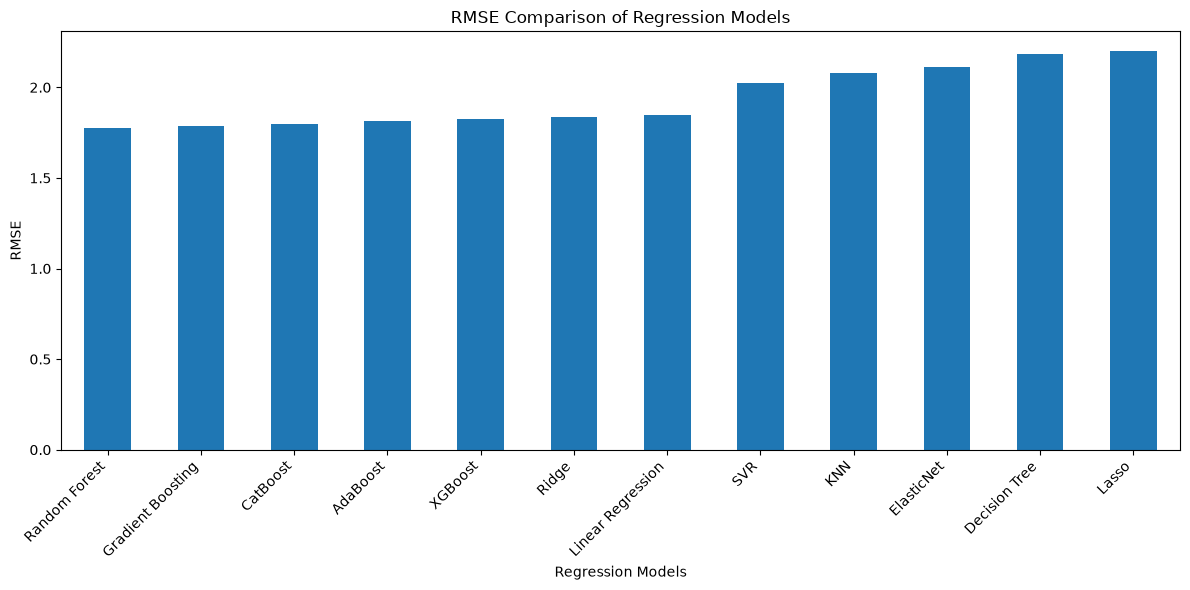

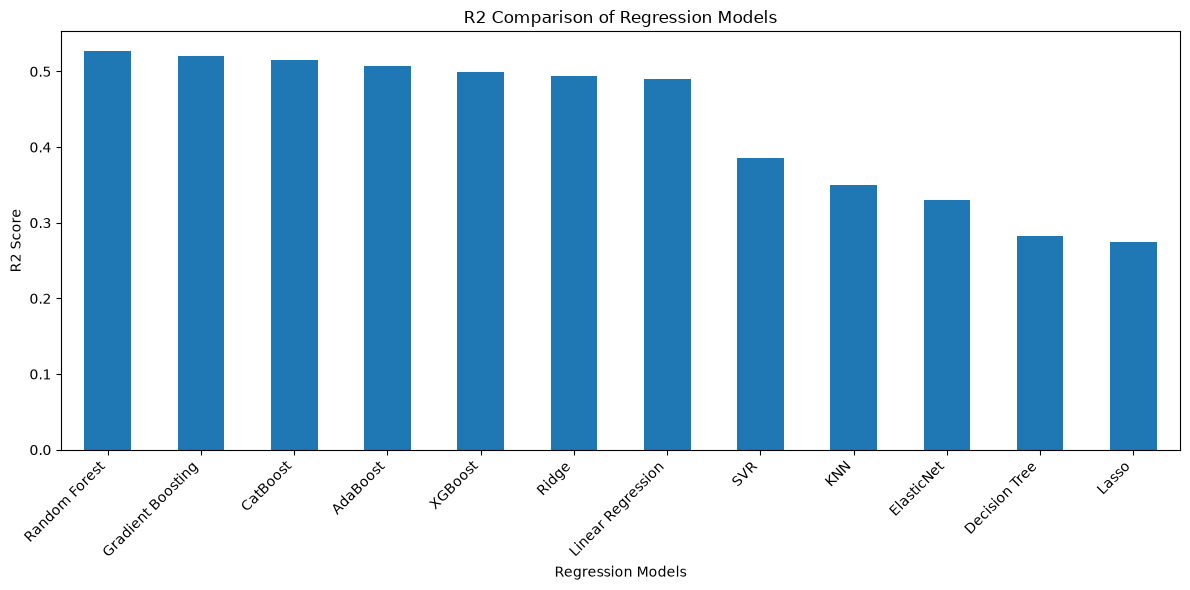

In [9]:
import matplotlib.pyplot as plt

# RMSE comparison
plt.figure(figsize=(12, 6))
results_df["RMSE"].sort_values().plot(kind="bar")
plt.title("RMSE Comparison of Regression Models")
plt.xlabel("Regression Models")
plt.ylabel("RMSE")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# R2 comparison
plt.figure(figsize=(12, 6))
results_df["R2"].sort_values(ascending=False).plot(kind="bar")
plt.title("R2 Comparison of Regression Models")
plt.xlabel("Regression Models")
plt.ylabel("R2 Score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Regression Model Evaluation - Observation

All 12 regression algorithms were trained and evaluated using the
same training and testing datasets.

Random Forest achieved the best overall performance, with the lowest
MAE (1.0065), MSE (3.1560), and RMSE (1.7765), and the highest R²
(0.5267).

Gradient Boosting and CatBoost also showed competitive performance.

The results indicate that ensemble-based models performed better
than most individual models in this experiment. However, the best
model explains approximately 52.67% of the variation in GlyHb
values, indicating that further improvement may be possible.

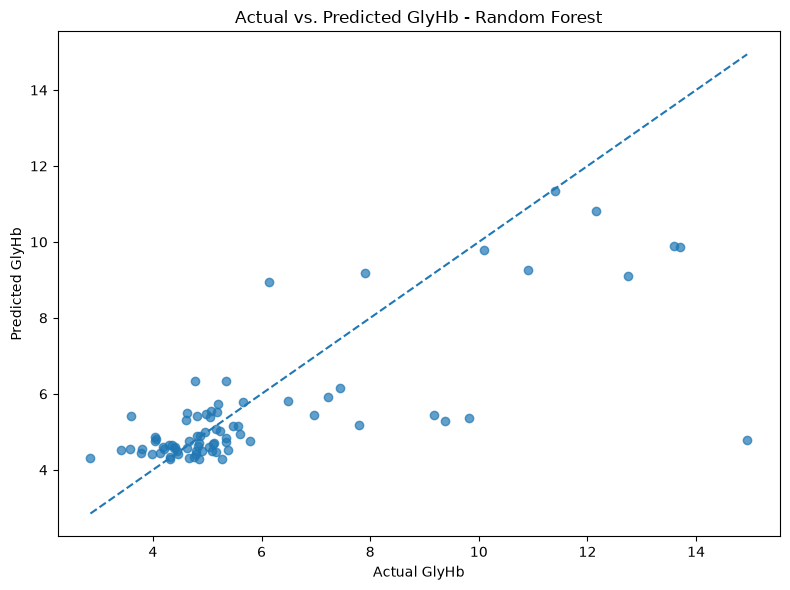

In [10]:
import matplotlib.pyplot as plt

# Get predictions from the best regression model
best_model = trained_models["Random Forest"]
y_pred = best_model.predict(X_test)

# Actual vs. predicted plot
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.7)

# Reference line for perfect predictions
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Actual vs. Predicted GlyHb - Random Forest")
plt.xlabel("Actual GlyHb")
plt.ylabel("Predicted GlyHb")
plt.tight_layout()
plt.show()

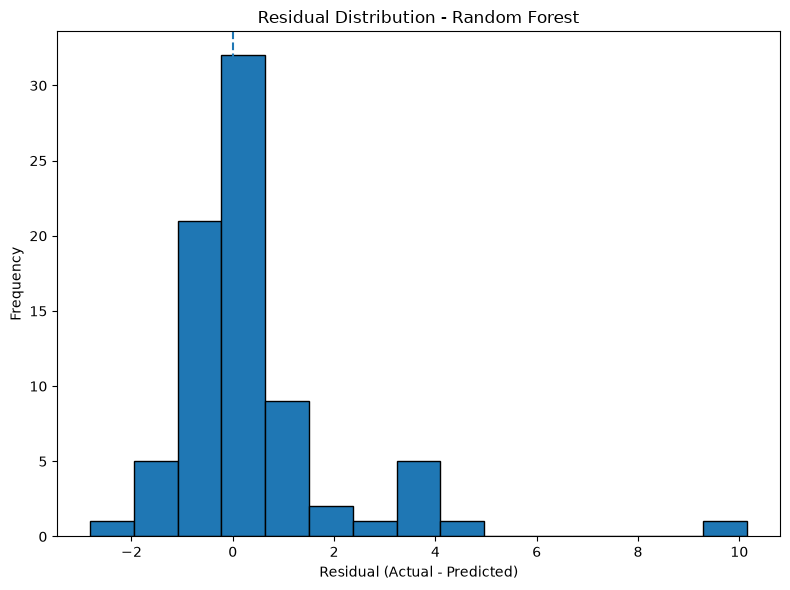

In [11]:
# Calculate prediction errors
residuals = y_test - y_pred

# Residual distribution
plt.figure(figsize=(8, 6))
plt.hist(residuals, bins=15, edgecolor="black")

plt.axvline(0, linestyle="--")
plt.title("Residual Distribution - Random Forest")
plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()